# Bài toán học máy

Câu lạc bộ lập trình phải đặt ghế cho buổi sinh hoạt thứ Bảy. Đặt thiếu thì người đến sau không có chỗ; đặt quá nhiều thì phòng chật. Chiều thứ Sáu, ta biết số người đã đăng ký và dự báo khả năng mưa. Ta chưa biết số người thực sự đến. Có thể dùng những buổi trước để dự đoán con số ấy không?

Đó là câu hỏi xuyên suốt bài này. Ta sẽ viết một baseline: phương án đơn giản, chạy được và cho một mốc so sánh. Trước khi học mô hình phức tạp, cần xác định một hàng dữ liệu đại diện cho gì, thông tin nào được phép dùng và kết quả sẽ được chấm thế nào.

> **Sau bài này, có thể**
>
> - Viết rõ input, output, thời điểm dự đoán và metric của một bài.
> - Phân biệt classification, regression và học không giám sát qua đầu ra cần tạo.
> - Dựng baseline scikit-learn, so với phương án đoán hằng số và đọc sai số.
> - Tạo bảng dự đoán có ID đúng thứ tự, kiểm shape và định dạng trước khi nộp.

## Từ câu chuyện đến một hàng dữ liệu

Mỗi hàng của bảng là một mẫu (sample), mỗi cột là một thông tin về mẫu. Ta quy ước mỗi hàng là **một buổi sinh hoạt**, không phải một học sinh. Đặc trưng (feature) là thông tin dùng để dự đoán; nhãn hay mục tiêu (target) là giá trị cần đoán. Bảng có thể chứa cả hai lúc huấn luyện, nhưng lúc sử dụng mô hình thì chỉ có đặc trưng.

| Cột | Ý nghĩa | Biết chiều thứ Sáu? | Dùng làm gì? |
|---|---|---|---|
| `session_id` | Mã buổi sinh hoạt | Có | Ghép kết quả với đúng buổi |
| `registered` | Số người đã đăng ký | Có | Feature |
| `rain_forecast` | Xác suất mưa được dự báo lúc chốt đăng ký | Có | Feature |
| `attendance` | Số người thực sự đến | Không | Target |

Không đưa `attendance` vào input. Cũng không thay `rain_forecast` bằng lượng mưa đo được sau buổi sinh hoạt: tên cột khác nhau chỉ một chút, nhưng thời điểm biết thông tin đã đổi. Bài 1.4 gọi những đường tắt như vậy là data leakage.



Bảng có cột cố định, mỗi dòng một bản ghi, gọi là dữ liệu có cấu trúc. Ảnh, âm thanh và văn bản tự do là dữ liệu phi cấu trúc, phải biến thành số trước khi vào mô hình, như ảnh chữ số dưới đây. Theo loại dữ liệu đầu vào, ứng dụng AI hay chia ba mảng: dữ liệu bảng (khoa học dữ liệu, như gợi ý quảng cáo từ lịch sử mua hàng), ảnh và video (thị giác máy tính), chữ và lời nói (xử lý ngôn ngữ tự nhiên).

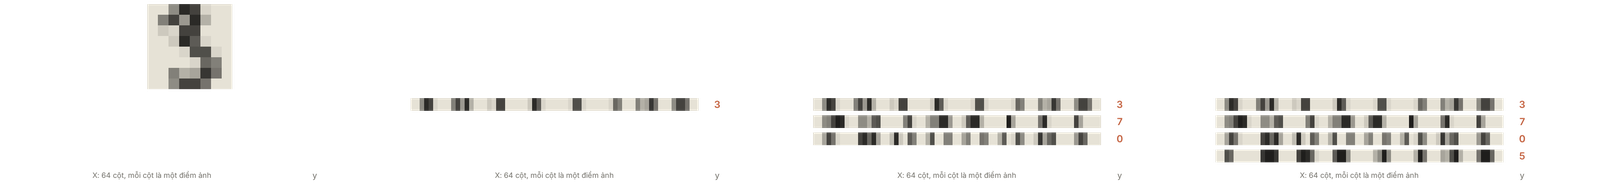

Hãy luôn viết một câu hợp đồng trước code: “Với mỗi buổi, từ dữ liệu có sẵn chiều thứ Sáu, dự đoán số người đến vào thứ Bảy; sai số đo bằng số người.” Câu này quyết định cách chọn cột, cách chia dữ liệu và cách đọc kết quả.

**Hỏi nhanh.** Câu lạc bộ muốn chạy mô hình vào chiều thứ Sáu để đoán số người đến buổi sáng thứ Bảy. Cột nào **không** được dùng làm feature?

- A. Số người đăng ký tính đến chiều thứ Sáu
- B. Số buổi câu lạc bộ đã tổ chức từ đầu học kỳ
- C. Dự báo mưa lưu lúc chiều thứ Sáu
- D. Số người quét mã vào cửa sáng thứ Bảy

<details><summary>Đáp án</summary>

D. Số người quét mã vào cửa sáng thứ Bảy

Số người quét mã sáng thứ Bảy chính là điều ta đang muốn đoán, và chỉ biết được sau khi buổi sinh hoạt diễn ra. Mô hình dùng cột này sẽ đạt điểm rất cao trên bảng cũ, nhưng chiều thứ Sáu thì chưa có cột ấy để đưa vào. Ba cột còn lại đều đã có từ chiều thứ Sáu.

</details>

## Đầu ra quyết định loại bài toán

Nếu hỏi “có ít nhất 30 người đến hay không?”, output là một nhãn trong hai lớp: đây là classification (phân loại). Nếu hỏi “có bao nhiêu người đến?”, output là một số: đây là regression (hồi quy). Số người là số nguyên, nhưng regression vẫn có thể dự đoán số thực như 28.4, hiểu là mức ước lượng. Có làm tròn hay không phải theo metric và quy định đầu ra.

Trong supervised learning (học có giám sát), mô hình học từ cặp $(\mathbf{x}_i,y_i)$: đặc trưng và nhãn của mẫu thứ $i$. Trong unsupervised learning (học không giám sát), ta chưa có nhãn mục tiêu; ví dụ chia các buổi thành nhóm theo kiểu hoạt động. Clustering không tự cho biết nhóm nào “tốt”, vì đó chưa phải câu hỏi mà dữ liệu trả lời.

Phân loại và hồi quy là hai dạng chính của học có giám sát. Số lớp có thể nhiều hơn hai: đọc chữ số viết tay có 10 lớp từ 0 tới 9, nhận cảm xúc trên khuôn mặt có một lớp cho mỗi cảm xúc. Loại đầu vào không quyết định loại bài: đoán tuổi từ ảnh khuôn mặt vẫn là hồi quy. Khi không có nhãn, ta có phân cụm (gom khách hàng hay gom bài báo chưa có chủ đề) và phát hiện bất thường. Khi chỉ một phần nhỏ dữ liệu có nhãn, học bán giám sát (semi-supervised) dùng thêm cả phần chưa có nhãn.

Ở đây chọn regression. Mô hình là một hàm $f$ nhận đặc trưng và trả dự đoán $\hat y=f(\mathbf{x})$. Huấn luyện là dùng những cặp cũ để chọn hàm đó. Dự đoán (inference) là áp dụng hàm đã chọn lên đặc trưng mới. Cùng một đoạn `predict` phải chạy được khi không có nhãn. Trong scikit-learn, huấn luyện là `model.fit(X_train, y_train)`, dự đoán là `model.predict(X_new)`; gọi `fit` lần nữa là học lại từ đầu.

Học máy là để thuật toán tự rút ra quy luật từ ví dụ thay vì người viết sẵn từng luật, và thường làm tốt hơn khi có thêm dữ liệu. Nó là một phần của AI, lĩnh vực rộng gồm cả các hệ thống chạy theo luật; học sâu là phần của học máy dùng mạng nơ-ron nhiều lớp (chương 3). Việc mô tả được bằng công thức hay luật cố định, như phanh theo tốc độ, bật đèn khi có tín hiệu hay đọc mã QR, thì viết chương trình là đủ. Học máy cần khi quy luật quá đa dạng để viết tay, như nhận con mèo trong ảnh hay đọc chữ viết tay: một chương trình chấm theo danh sách từ khóa không theo kịp từ mới, còn mô hình học thêm được từ ví dụ mới. Dữ liệu càng nhiều và quy luật càng phức tạp thì mạng nơ-ron càng có lợi; dữ liệu ít thì mô hình đơn giản an toàn hơn. Mỗi hệ thống AI hiện nay thường chỉ giỏi một việc hẹp.



**Hỏi nhanh.** Input là ảnh chụp một bài giải. Output là một trong ba nhãn “đúng”, “sai”, “chưa đủ bước”. Đây là loại bài toán nào?

- A. Regression, vì nhãn mã hóa được thành 0, 1, 2
- B. Classification có giám sát, với ba lớp
- C. Clustering, vì cần chia bài giải thành ba nhóm
- D. Classification nhị phân, đúng hoặc không đúng

<details><summary>Đáp án</summary>

B. Classification có giám sát, với ba lớp

Mã 0, 1, 2 chỉ là tên lớp, lớp 2 không “lớn gấp đôi” lớp 1. Clustering dùng khi dữ liệu không có nhãn, còn ở đây đề đã cho sẵn ba lớp. “Sai” và “chưa đủ bước” là hai lớp khác nhau, nên không gộp lại thành bài nhị phân được.

</details>

## Tạo một bộ dữ liệu có thể kiểm chứng

Ta tự sinh 120 buổi. Công thức giả định rằng số đến tăng theo đăng ký, giảm theo dự báo mưa, cộng thêm nhiễu do những yếu tố không ghi lại. Vì tự sinh nên ta biết quy luật thật, và có thể đối chiếu xem mô hình học được bao nhiêu phần của nó.

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(11)
n = 120
registered = rng.integers(15, 65, size=n)
rain_forecast = rng.uniform(0, 1, size=n)
attendance = np.rint(
    4 + 0.75 * registered - 7 * rain_forecast
    + rng.normal(0, 2, size=n)
).clip(0)
data = pd.DataFrame({
    "session_id": np.arange(n),
    "registered": registered,
    "rain_forecast": rain_forecast,
    "attendance": attendance,
})
X = data[["registered", "rain_forecast"]]
y = data["attendance"]
print(X.shape, y.shape)
print(data.head(3).round(2).to_string(index=False))

(120, 2) (120,)
 session_id  registered  rain_forecast  attendance
          0          21           0.02        19.0
          1          21           0.84        15.0
          2          54           0.47        41.0


Nhìn shape trước: `X` có 120 hàng, hai cột; `y` có 120 phần tử. `data[[...]]` chọn một bảng hai chiều; `data["attendance"]` chọn một vector nhãn. Mã buổi vẫn nằm trong `data`, nhưng không xuất hiện trong `X`. Không có lý do chung nào để số thứ tự tự nó dự đoán số người đến.

**Hỏi nhanh.** `session_id` chạy từ 0 đến 119 theo thứ tự thời gian. Vì sao không đưa cột này vào `X`?

- A. ID chỉ là mã để ghép kết quả, buổi mới sẽ có ID chưa từng thấy
- B. Đưa vào cũng không sao, mô hình tự bỏ qua cột vô dụng
- C. Nên đưa vào, miễn là chuẩn hóa trước cho cùng thang
- D. Phải đưa vào để dự đoán giữ đúng thứ tự các buổi

<details><summary>Đáp án</summary>

A. ID chỉ là mã để ghép kết quả, buổi mới sẽ có ID chưa từng thấy

Mô hình tuyến tính cũng gán cho ID một hệ số như mọi cột khác. Với 80 buổi, nó có thể bắt được một “xu hướng” chỉ do nhiễu. Đến buổi mới, ID lớn hơn mọi ID đã thấy, và mô hình kéo dài xu hướng không có thật ấy ra. Thứ tự dự đoán do bảng kết quả giữ, không phải việc của feature. Nếu thật sự có xu hướng theo thời gian, hãy tạo feature có nghĩa như tháng, mùa hay số buổi đã tổ chức.

</details>

| Đại lượng | Shape | Một phần tử nói gì? |
|---|---|---|
| $X$ | `(120, 2)` | Hai feature của một buổi |
| $\mathbf y$ | `(120,)` | Số người đến |
| $\hat{\mathbf y}$ | `(số_buổi_cần_đoán,)` | Một dự đoán cho mỗi buổi |

## Ba phần dữ liệu, ba công việc

Ta giả định các hàng đang xếp theo thứ tự buổi. Dùng 80 buổi đầu để học (train), 20 buổi sau để so sánh phương án (validation), 20 buổi cuối để báo cáo cuối (test). Tỉ lệ này chỉ phục vụ ví dụ; dữ liệu thật còn phụ thuộc số mẫu, nhóm và thời gian. Train để mô hình học. Validation để so sánh và chọn cấu hình, như số vòng huấn luyện hay độ mạnh regularization. Test giữ riêng tới cuối và chỉ chấm một lần, nên điểm trên test gần với điểm trên dữ liệu mới; dùng test để chọn giữa nhiều phương án thì điểm báo cáo đẹp hơn thực tế. So hai mô hình phải chấm trên cùng một tập.



Test có nhãn trong bài để ta mô phỏng phép đánh giá. Trong cuộc thi, nhãn test thường không được cung cấp; tập dùng để xuất bài nộp cũng hay được gọi là `test`. Cần phân biệt tập đánh giá độc lập có nhãn được giữ riêng với tập dự đoán không có nhãn của đề.

In [ ]:
train_rows = np.arange(0, 80)
valid_rows = np.arange(80, 100)
test_rows = np.arange(100, 120)
X_train, y_train = X.iloc[train_rows], y.iloc[train_rows]
X_valid, y_valid = X.iloc[valid_rows], y.iloc[valid_rows]
X_test, y_test = X.iloc[test_rows], y.iloc[test_rows]
print(len(train_rows), len(valid_rows), len(test_rows))
print(len(set(train_rows) & set(test_rows)))

80 20 20
0


Dòng cuối phải bằng 0: không có hàng nào vừa học vừa chấm test. Đó là điều kiện cần nhưng chưa đủ: nếu một buổi bị ghi thành hai hàng, hay nhiều hàng cùng thuộc một nhóm gắn bó (cùng trường, cùng người), còn phải chia theo nhóm, bài 1.3 sẽ làm.

**Hỏi nhanh.** Có hai mô hình, ta cần chọn một. Ta so điểm của chúng trên tập nào?

- A. Validation
- B. Train, vì mô hình đã học trên đó
- C. Test, tập đã giữ riêng từ đầu
- D. Gộp train và test lại

<details><summary>Đáp án</summary>

A. Validation

Validation là phần dữ liệu giữ riêng để so và chọn. Điểm trên train thường đẹp vì mô hình đã thấy chính các mẫu ấy, nên không cho biết nó đoán buổi mới tốt đến đâu. Test để dành cho câu hỏi sau cùng: phương án đã chốt chạy thế nào trên dữ liệu chưa hề dùng để quyết định gì.

</details>

## Baseline và một thước đo đọc được

Ta dùng mean absolute error (MAE): trung bình trị tuyệt đối của các sai số. Với $m$ mẫu đang chấm,

$$\operatorname{MAE}=\frac{1}{m}\sum_{i=1}^{m}|\hat y_i-y_i|.$$

MAE bằng 2 nghĩa là trung bình độ lệch có độ lớn hai người; không có nghĩa mọi buổi đều sai đúng hai người. Số càng nhỏ càng tốt. Bài 1.6 sẽ so với những metric khác.

Baseline hằng số dùng `DummyRegressor(strategy="mean")`: dự đoán mọi buổi bằng trung bình **train**. Phương án thứ hai là `LinearRegression`, cộng các đóng góp của hai feature. Ta chưa cần tự cài thuật toán tìm hệ số; bài 2.1 sẽ giải thích cách học nó. Với bài phân loại, baseline tương ứng là luôn đoán lớp đông nhất: dữ liệu có 70% khách ở lại thì luôn đoán “ở lại” đã đạt accuracy 70%.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

models = {
    "mean": DummyRegressor(strategy="mean"),
    "linear": LinearRegression(),
}
valid_mae = {}
for name, model in models.items():
    model.fit(X_train, y_train)             # chỉ học từ train
    prediction = model.predict(X_valid)
    assert prediction.shape == y_valid.shape
    valid_mae[name] = mean_absolute_error(y_valid, prediction)
    print(name, f"valid MAE = {valid_mae[name]:.3f}")
chosen_name = min(valid_mae, key=valid_mae.get)
print("Chọn bằng validation:", chosen_name)

mean valid MAE = 10.740
linear valid MAE = 1.561
Chọn bằng validation: linear


So hai dòng `valid MAE` trên cùng 20 buổi: đoán hằng số sai trung bình gần 11 người, linear chỉ sai khoảng 1.6 người. Số đăng ký và dự báo mưa mang gần hết thông tin cần thiết, đúng như công thức sinh dữ liệu. Baseline hằng số còn một vai trò nữa: nó là mốc tối thiểu để phát hiện lỗi.



**Hỏi nhanh.** Trên cùng 20 buổi validation, một mô hình mới có MAE 11.5 người, còn baseline đoán hằng số có MAE 10.74. Ta nên làm gì tiếp?

- A. Giữ mô hình mới, vì nó dùng nhiều thông tin hơn
- B. Bỏ baseline đi, vì đoán hằng số không phải mô hình
- C. Tìm lỗi trong dữ liệu hoặc trong cách tính điểm
- D. Tính thêm điểm trên test để có thêm ý kiến

<details><summary>Đáp án</summary>

C. Tìm lỗi trong dữ liệu hoặc trong cách tính điểm

Thua cả cách đoán không nhìn feature nào là dấu hiệu có lỗi: cột bị lệch, shape sai, dùng nhầm tập, hay quên chuẩn hóa. Baseline có ích chính vì nó cho ta một mức tối thiểu như vậy. Còn mở test ra để “hỏi thêm” thì test không còn độc lập nữa.

</details>

Ta chốt lựa chọn, học lại trên train cộng validation rồi chấm test đúng một lần. Sau khi đã xem test, mọi chỉnh sửa tiếp theo đều biến nó thành một tập validation khác.

In [ ]:
final_model = models[chosen_name]
final_model.fit(X.iloc[:100], y.iloc[:100])
test_prediction = final_model.predict(X_test)
print(f"Test MAE = {mean_absolute_error(y_test, test_prediction):.3f}")

Test MAE = 1.317


Đọc theo đơn vị “người” để trả lời câu hỏi đặt ghế: dự đoán lệch trung bình chừng một, hai người, nên đặt thêm vài ghế dự phòng là đủ; MAE là trung bình nên có buổi vẫn lệch nhiều hơn. Con số này đo trên 20 buổi nên còn dao động, và nó chỉ đúng chừng nào câu lạc bộ còn giống những buổi đã thấy; nếu quy mô đột ngột đổi, mô hình phải học lại.

## Ví dụ tính tay và kiểm bảng kết quả

Ba buổi có số người thật $(20,30,40)$, dự đoán $(18,33,39)$. Sai số là $(-2,3,-1)$; MAE $=(2+3+1)/3=2$ người. Trung bình sai số có dấu bằng 0, nhưng dự đoán vẫn sai. Trị tuyệt đối chặn việc sai cao và sai thấp triệt tiêu nhau.



Giả sử đề yêu cầu CSV gồm `session_id,attendance`. Ta tạo bảng trong bộ nhớ, giữ ID theo thứ tự input, và đọc lại bằng pandas như một phép kiểm vòng kín.

In [ ]:
from io import StringIO

submission = pd.DataFrame({
    "session_id": data.iloc[test_rows]["session_id"].to_numpy(),
    "attendance": test_prediction,
})
csv_text = submission.to_csv(index=False)
read_back = pd.read_csv(StringIO(csv_text))
assert list(read_back.columns) == ["session_id", "attendance"]
assert read_back["session_id"].is_unique
assert np.isfinite(read_back["attendance"]).all()
assert read_back["session_id"].tolist() == list(test_rows)
print(read_back.head(3).round(2).to_string(index=False))
print("Số hàng:", len(read_back))

 session_id  attendance
        100       16.19
        101       26.21
        102       42.31
Số hàng: 20


`index=False` tránh thêm một cột số thứ tự ngoài ý muốn. Với đề thật, tên cột và định dạng lấy đúng theo đề; các `assert` trên là danh sách kiểm cần sửa theo.

**Hỏi nhanh.** Một bạn sắp xếp cột dự đoán từ nhỏ đến lớn nhưng để nguyên cột ID. File nộp còn đúng không?

- A. Đúng, vì số hàng và số cột vẫn khớp với đề
- B. Đúng, vì MAE không phụ thuộc thứ tự hàng
- C. Sai, vì phải sắp theo ID tăng dần
- D. Sai, vì dự đoán đã bị ghép nhầm sang mẫu khác

<details><summary>Đáp án</summary>

D. Sai, vì dự đoán đã bị ghép nhầm sang mẫu khác

Đúng shape chỉ mới đúng số lượng. MAE so dự đoán với nhãn **có cùng ID**. Sắp lại cột dự đoán thì các số bị chuyển sang ID khác, nên điểm sai dù tập giá trị vẫn y nguyên. Thứ tự ID là do đề quy định; điều bắt buộc là mỗi ID đi với đúng dự đoán của nó.

</details>

## Lần nộp đầu tiên

Đề Thực hành đầu tiên, [Hình chữ nhật ẩn](https://lqdoj.edu.vn/problem/aicanuc80kl01) (ROAI 2025), cho các điểm trên hình vuông $[0, 100]^2$: điểm trong một hình chữ nhật ẩn có nhãn 1, ngoài là 0. Input là tọa độ `X`, `Y`; output là nhãn của từng `datapointID`; metric là accuracy.

Cách đơn giản: lấy hình chữ nhật nhỏ nhất chứa mọi điểm train nhãn 1, điểm test nào nằm trong thì đoán 1. Thử trên dữ liệu tự sinh với 30 điểm train, như kịch bản khó nhất của đề:

In [ ]:
rng = np.random.default_rng(5)
x_lo, x_hi, y_lo, y_hi = 20, 65, 30, 80                 # hình chữ nhật ẩn, chỉ dùng để sinh dữ liệu


def make_points(n):
    points = rng.uniform(0, 100, size=(n, 2))
    inside = (points[:, 0] >= x_lo) & (points[:, 0] <= x_hi) & (points[:, 1] >= y_lo) & (points[:, 1] <= y_hi)
    return pd.DataFrame({"X": points[:, 0], "Y": points[:, 1], "label": inside.astype(int)})


train_pts, test_pts = make_points(30), make_points(3000)
pos = train_pts[train_pts["label"] == 1]
box = (pos["X"].min(), pos["X"].max(), pos["Y"].min(), pos["Y"].max())
answer = (test_pts["X"].between(box[0], box[1]) & test_pts["Y"].between(box[2], box[3])).astype(int)
print("số điểm nhãn 1 trong train:", len(pos))
print("hộp học được:", [round(float(v), 1) for v in box])
print("accuracy đoán toàn 0:", round(float((test_pts["label"] == 0).mean()), 3))
print("accuracy hộp nhỏ nhất:", round(float((answer == test_pts["label"]).mean()), 3))
sub_pts = pd.DataFrame({"subtaskID": 3, "datapointID": np.arange(len(test_pts)), "answer": answer})
print(sub_pts.head(3).to_string(index=False))

số điểm nhãn 1 trong train: 5
hộp học được: [20.3, 50.3, 32.0, 79.9]
accuracy đoán toàn 0: 0.773
accuracy hộp nhỏ nhất: 0.917
 subtaskID  datapointID  answer
         3            0       0
         3            1       1
         3            2       0




Chỉ 5 điểm nhãn 1 đã cho accuracy 0.917, so với 0.773 khi đoán toàn 0. Cạnh phải dừng ở 50.3 trong khi hộp thật kéo tới 65: hộp nhỏ nhất luôn nằm bên trong hộp thật, nên mọi lỗi là đoán 0 cho điểm sát biên. Điểm nhãn 0 trong train cho biết biên có thể nới tới đâu.

Để nộp: tải dữ liệu ở trang đề, chạy `baseline.ipynb`, nộp `submission.zip` trên LQDOJ với kiểu **Output**. Ở đề thật, `datapointID` lấy từ `test.csv`, mỗi kịch bản một hình chữ nhật riêng.

## Từ mô hình tới sản phẩm

Một dự án AI đi qua các bước: xác định bài toán, thu thập và làm sạch dữ liệu, huấn luyện, đánh giá, triển khai, theo dõi. Bước đầu trả lời ai gặp vấn đề, vấn đề là gì, xảy ra ở đâu và vì sao đáng giải (khung 4W), rồi mới viết hợp đồng như ở đầu bài.

Dữ liệu phải liên quan tới bài toán và đáng tin: lấy từ khảo sát, phỏng vấn, cảm biến, giao dịch hay kho dữ liệu công khai, không từ tin đồn hay suy đoán. Dữ liệu lớn (big data) sinh liên tục ở dạng số, từ giao dịch ngân hàng, máy móc, cảm biến, mạng xã hội. Nhãn thường do người gán, có khi chia nhỏ cho rất nhiều người (crowdsourcing), có khi để một mô hình gán trước rồi người sửa chỗ sai. Hướng dẫn gán nhãn mơ hồ hay dịch sai làm nhãn sai hàng loạt. Hai người gán cùng 100 mẫu mà chỉ đồng ý ở 60 thì mô hình khó vượt mức đó; cần viết lại hướng dẫn, thêm ví dụ cho ca khó, rồi đo lại độ đồng thuận.

Triển khai (deploy) là đưa mô hình lên máy chủ hay thiết bị để ứng dụng gửi dữ liệu tới và nhận dự đoán về. Sau đó trọng số đứng yên: mô hình không tự giỏi lên theo số lần dùng. Muốn tốt hơn phải gom dữ liệu mới, huấn luyện lại và cập nhật bản mới; dữ liệu ngoài đời đổi dần nên vẫn phải theo dõi sai số.

Mô hình học cả định kiến có trong dữ liệu: văn bản trên mạng hay gắn bác sĩ với nam, y tá với nữ. Dữ liệu không đại diện cũng làm kết quả lệch, như dữ liệu tín dụng chỉ lấy từ người đã có thẻ; người tạo dữ liệu còn có thiên kiến vô thức, như ưu tiên những gì ở gần mình. Một thuật toán khó giải thích là vấn đề minh bạch, không tự làm kết quả lệch về phía nào. Dữ liệu cá nhân như khuôn mặt, số điện thoại, địa chỉ cần được người trong đó đồng ý, được ẩn hoặc xóa trước khi huấn luyện, và chỉ dùng đúng mục đích đã nói. Để đếm người qua camera thì không cần biết đó là ai: làm mờ khuôn mặt hoặc chỉ lưu con số; xử lý ngay trên thiết bị giữ video không rời khỏi nhà. Hệ thống ra quyết định về con người, như chấm ứng viên hay tính bảo hiểm, cần cẩn trọng hơn hệ thống vẽ bản đồ đáy biển; với chẩn đoán bệnh, mô hình gợi ý còn bác sĩ quyết định. Kẻ xấu có thể chèn mẫu giả vào dữ liệu huấn luyện (đầu độc dữ liệu), và dán tài liệu nội bộ vào một công cụ AI công cộng chưa được phép có thể làm lộ thông tin.

## Bẫy cài đặt

`model.score` không luôn trả metric đề cần: với regression thường là $R^2$, còn với classifier thường là accuracy. Trong ví dụ ta gọi `mean_absolute_error` tường minh. Hai metric có thể xếp hạng phương án khác nhau.

Nếu đọc nhãn bằng `data[["attendance"]]`, shape sẽ là `(n,1)`; khi tự trừ với dự đoán `(n,)`, NumPy có thể tạo ma trận `(n,n)`. Hãy giữ nhãn một chiều và kiểm shape. Không đưa ID vào mô hình chỉ vì nó là số; trước hết hỏi mã đó có ý nghĩa ở thời điểm sử dụng không.

## Khi đi thi

- **Viết hợp đồng trước code:** đơn vị mẫu, nhãn, metric, cột output, thứ tự ID, thời điểm dự đoán.
- **Nộp một baseline sớm:** đoán hằng số hay trung bình nhóm, để kiểm cả đường đi tới file nộp lẫn có mốc so sánh.
- **Chấm đúng metric của đề:** gọi hàm metric tường minh; nếu đề có scorer local, đối chiếu cùng một bảng dự đoán với scorer đó.
- **Đọc quy định môi trường** (Internet, dữ liệu ngoài, GPU) từ thông báo của chính cuộc thi.

## Tóm tắt

- Bài học máy bắt đầu bằng đơn vị mẫu, thời điểm dự đoán, input và output.
- Train học; validation chọn; test độc lập báo cáo sau khi chốt.
- Baseline chỉ có giá trị khi chấm đúng metric trên cùng dữ liệu.
- Bảng dự đoán cần đúng cả shape, giá trị và quan hệ với ID.

## Kiểm tra cuối bài

**Câu 1.** Một bảng có 12 trường, mỗi trường ghi lại 8 buổi sinh hoạt. Ta cần đoán số người đến từng buổi. Mỗi mẫu là gì, và target của nó là gì?

- A. Mỗi mẫu là một cột, target là tổng của cột ấy
- B. Mỗi mẫu là một buổi, target là số người thực sự đến buổi ấy
- C. Mỗi mẫu là một trường, target là số người đến trung bình qua 8 buổi
- D. Mỗi mẫu là một người, target là số buổi người ấy tham gia

<details><summary>Đáp án</summary>

B. Mỗi mẫu là một buổi, target là số người thực sự đến buổi ấy

Ta đoán cho từng buổi sinh hoạt, nên mỗi buổi là một mẫu và có tất cả 96 mẫu. Mã trường có thể dùng làm feature, hoặc dùng để chia dữ liệu theo trường.

</details>
**Câu 2.** Đề yêu cầu đoán số người đến từng buổi và chấm bằng MAE. Một bạn trong nhóm đổi sang bài phân loại “đông” (từ 30 người trở lên) hay “vắng” cho dễ huấn luyện. Làm vậy sai ở đâu?

- A. Không sai, vì phân loại thường chính xác hơn hồi quy
- B. Đầu ra không còn là thứ đề chấm bằng MAE
- C. Phân loại cần nhiều dữ liệu hơn nên không chạy được
- D. Nhãn “đông” hay “vắng” để lộ thông tin của buổi

<details><summary>Đáp án</summary>

B. Đầu ra không còn là thứ đề chấm bằng MAE

Loại bài toán do đầu ra mà đề yêu cầu quyết định. Nhãn “đông” không cho biết thiếu 2 ghế hay 20 ghế, và MAE cũng không chấm được một cái nhãn. Ngưỡng 30 người chỉ dùng được khi chính đề hỏi như vậy.

</details>
**Câu 3.** Bảng chỉ có feature của từng buổi, không có cột nhãn. Ta muốn gom các buổi giống nhau thành từng nhóm. Đây là loại bài toán nào?

- A. Học không giám sát, chẳng hạn clustering
- B. Học có giám sát, vì feature đã là số
- C. Classification có giám sát
- D. Regression có giám sát

<details><summary>Đáp án</summary>

A. Học không giám sát, chẳng hạn clustering

Không có nhãn thì không có cặp feature và nhãn để học, nên đây không phải học có giám sát, dù feature đã là số. Clustering chỉ tìm cấu trúc trong feature. Nó gom được nhóm, nhưng không tự nói nhóm nào “tốt”.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 1.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=1)

</details>
**Câu 4.** Một mô hình được huấn luyện và kiểm trên dữ liệu năm 2023: đúng 99.8% trên train, 92% trên validation. Đem dùng cho dữ liệu năm 2025 thì chỉ còn đúng 64%. Vấn đề chính nằm ở đâu?

- A. Dữ liệu năm 2025 đã khác dữ liệu năm 2023
- B. Validation cùng năm với train nên con số 92% là ảo
- C. Dữ liệu năm 2025 bị gán nhãn sai nên điểm thấp giả tạo
- D. Mô hình quá yếu, dù đúng tới 99.8% trên train

<details><summary>Đáp án</summary>

A. Dữ liệu năm 2025 đã khác dữ liệu năm 2023

Con số 92% đã ước lượng khá tốt cho dữ liệu cùng thời kỳ. Điểm chỉ tụt xuống 64% khi sang thời kỳ khác. Mô hình quá yếu thì không đạt 99.8% trên train. Chia dữ liệu theo thời gian như mục “Ba phần dữ liệu” giúp phát hiện sớm loại lỗi này: validation nên là giai đoạn gần nhất trước lúc đem mô hình ra dùng.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 286](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=108)

</details>
**Câu 5.** Hai mẫu có nhãn thật là 10 và 20. Mô hình đoán 13 và 19. MAE bằng bao nhiêu?

- A. 1
- B. 4
- C. 5
- D. 2

<details><summary>Đáp án</summary>

D. 2

MAE là trung bình của các sai số tuyệt đối: $(|13-10|+|19-20|)/2 = (3+1)/2 = 2$. Ra 4 là lấy tổng sai số mà quên chia cho số mẫu.

</details>
**Câu 6.** Baseline `DummyRegressor(strategy="mean")` đoán mọi buổi bằng một số trung bình. Số trung bình ấy phải tính trên tập nào?

- A. Validation
- B. Test
- C. Train
- D. Cả ba tập

<details><summary>Đáp án</summary>

C. Train

Baseline cũng là một mô hình, và số trung bình ấy là tất cả những gì nó học. Giống mọi mô hình khác, nó chỉ được học từ train. Tính trung bình trên validation hay test là đã cho baseline xem trước đáp án.

</details>
**Câu 7.** Đề chấm bằng MAE. Trên cùng tập validation, mô hình A có MAE 3 và sai số lớn nhất là 7. Mô hình B có MAE 4 và sai số lớn nhất là 5. Ta chọn mô hình nào?

- A. A, vì tổng hai con số của A nhỏ hơn
- B. A, vì MAE thấp hơn
- C. B, vì sai số lớn nhất nhỏ hơn
- D. B, vì hai con số của B gần nhau hơn

<details><summary>Đáp án</summary>

B. A, vì MAE thấp hơn

Ta chọn theo đúng thước đo mà đề chấm, và MAE 3 thấp hơn 4. Sai số lớn nhất giúp ta xem mô hình có đoán trật hẳn mẫu nào không, nhưng không thay được tiêu chí chọn mà đề đã định.

</details>
**Câu 8.** Validation chỉ gồm các trường đã có trong train. Trên đó, baseline có MAE 8, còn linear có MAE 2. Ta muốn dùng mô hình cho trường mới. Nên làm thí nghiệm nào tiếp theo?

- A. Chia ngẫu nhiên thêm nhiều lần, lấy lần có điểm tốt nhất
- B. Học lại linear trên cả validation rồi tính MAE ngay trên đó
- C. Giữ cách chia cũ, chỉ làm tròn MAE cho gọn
- D. Để riêng toàn bộ vài trường ra, rồi so lại hai mô hình

<details><summary>Đáp án</summary>

D. Để riêng toàn bộ vài trường ra, rồi so lại hai mô hình

Điều ta cần biết là mô hình đoán thế nào cho một trường chưa từng thấy. MAE 2 hiện tại chỉ cho biết linear tốt hơn trên những trường đã quen. Để riêng hẳn vài trường làm validation thì mới trả lời được câu hỏi ấy.

</details>
**Câu 9.** Một đội thử vài mô hình, chọn mô hình có điểm test cao nhất, rồi báo điểm test ấy là đánh giá độc lập. Làm vậy có đúng không?

- A. Đúng, vì test không dùng trong `fit`
- B. Đúng, nếu chỉ thử hai mô hình
- C. Sai, vì test đã được dùng để chọn
- D. Đúng, nếu điểm test cao hơn validation

<details><summary>Đáp án</summary>

C. Sai, vì test đã được dùng để chọn

Test đã được dùng để chọn, nên điểm của mô hình thắng có lẫn phần may mắn trên chính tập ấy. Thông tin của test có thể lọt vào qua quyết định của người làm, không chỉ qua lệnh `fit`. Muốn chọn mô hình thì dùng validation.

</details>
**Câu 10.** Ghi file nộp bằng pandas. Viết thế nào để file không có thêm cột index?

- A. `to_csv(index=True)`
- B. `sort_values("attendance")`
- C. `reset_index()` rồi xuất mọi cột
- D. `to_csv(index=False)`

<details><summary>Đáp án</summary>

D. `to_csv(index=False)`

`to_csv` mặc định ghi cả index thành một cột thừa, còn `index=False` thì bỏ cột ấy đi. Sắp xếp hay `reset_index()` đều không bỏ được index. Ghi xong vẫn nên đọc lại file để kiểm tên các cột so với đề.

</details>
## Đọc thêm

- James, Witten, Hastie, Tibshirani và Taylor — [An Introduction to Statistical Learning](https://www.statlearning.com/), chương 2. Đọc để phân biệt dự đoán, suy luận và các loại bài toán học thống kê.
- [scikit-learn — DummyRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html). Xem các baseline hằng số và ý nghĩa của `strategy`.
- [scikit-learn — Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html). Tra đúng hàm metric thay vì mặc định dùng `model.score`.

Nguồn ảnh: ảnh chữ số lấy từ bộ `load_digits` của scikit-learn (UCI, CC BY 4.0).